# Reto 4: restauración de imágenes SAR con SwinIR

Usamos las imágenes SAR del reto 3 (*SAR despeckling filters dataset*, `Noisy_val` / `GTruth_val`). Restauramos con **SwinIR** preentrenado, sin entrenar ni reentrenar nada, y medimos el resultado frente al ground truth con las mismas métricas del reto 3.

Siguiendo la idea del artículo *Analysis of the effects of applying a restoration process to despeckled SAR imagery*, comparamos seis versiones de cada imagen:

| Versión | Proceso |
|---|---|
| Ruidosa | Imagen original con speckle |
| SwinIR σ=25 | Ruidosa → SwinIR denoising (σ = 25) |
| SwinIR σ=50 | Ruidosa → SwinIR denoising (σ = 50) |
| CDAE | Ruidosa → CDAE ajustado del reto 3 |
| CDAE + SwinIR σ=15 | Ruidosa → CDAE → SwinIR denoising (σ = 15) |
| CDAE + SwinIR Real-SR | Ruidosa → CDAE → SwinIR Real-SR ×2 → reducción a 512×512: restauración de la imagen ya filtrada |

SwinIR es el modelo de restauración con Transformer de Liang et al. (2021). Usamos los pesos oficiales de *grayscale denoising* y de *real-world super-resolution* ×2 con GAN (SwinIR-M). El CDAE es el autoencoder que ya entrenamos en el reto 3 y aquí solo se usa para predecir.

In [1]:
import os
import re
import time
import warnings
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from skimage.metrics import structural_similarity

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import keras
from network_swinir import SwinIR

torch.set_num_threads(16)

DATA = Path("SAR despeckling filters dataset/Main folder")
CDAE_PATH = Path("../reto-3/modelos/cdae_ajustado.keras")
PESOS = Path("pesos")
RES = Path("resultados")
RES.mkdir(exist_ok=True)

SEED = 123      # misma semilla del reto 3
ENL_WIN = 20
ENL_K = 3

## Imágenes

Tomamos las mismas tres imágenes de la validación oficial que usamos en el análisis visual del reto 3 (índices 1, 59 y 67, elegidos con la semilla 123). Tienen zonas homogéneas, bordes finos y una zona urbana.

In [2]:
def natural_key(path):
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", path.name)]


def read_gray(path):
    return cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_GRAYSCALE)


gt_files = sorted((DATA / "GTruth_val").glob("*.tiff"), key=natural_key)
noisy_files = sorted((DATA / "Noisy_val").glob("*.tiff"), key=natural_key)
assert [p.name for p in gt_files] == [p.name for p in noisy_files]

IDX = sorted(np.random.default_rng(SEED).choice(len(gt_files), size=3, replace=False).tolist())
names = [gt_files[i].stem for i in IDX]
gt = np.stack([read_gray(gt_files[i]) for i in IDX]).astype(np.float32)
noisy = np.stack([read_gray(noisy_files[i]) for i in IDX]).astype(np.float32)
print("Imágenes:", dict(zip(IDX, names)), "| tamaño:", gt.shape[1:])

Imágenes: {1: '5120_512', 59: '5632_4608', 67: '5632_8704'} | tamaño: (512, 512)


## Métricas

Son las del reto 3, calculadas por imagen frente al GT en escala 0–255:

- **PSNR** y **SSIM**: fidelidad frente al GT (mayor es mejor).
- **ENL** = μ²/σ² en las 3 ventanas de 20×20 más homogéneas del GT. Un ENL más alto que el del GT indica sobresuavizado, así que reportamos también **ENL / ENL_GT** (ideal ≈ 1).
- **Ratio de gradientes** (Sobel, salida / GT): menor que 0.8 indica bordes perdidos; mayor que 1.2, ruido residual o artefactos.
- **Correlación de bordes**: correlación entre los mapas de gradiente de la salida y del GT.

In [3]:
def grad_mag(img):
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    return np.sqrt(gx ** 2 + gy ** 2)


def find_homogeneous_rois(img, win=ENL_WIN, k=ENL_K, stride=4):
    # ventanas con menor sigma/mu, sin zonas negras, saturadas ni constantes
    f = img.astype(np.float64)
    ii, ii2 = cv2.integral(f), cv2.integral(f * f)
    box = lambda a: a[win:, win:] - a[:-win, win:] - a[win:, :-win] + a[:-win, :-win]
    mean = box(ii) / win ** 2
    std = np.sqrt(np.maximum(box(ii2) / win ** 2 - mean ** 2, 0))
    cv = std / np.maximum(mean, 1e-9)
    cv[(mean < 30) | (mean > 245) | (std < 1)] = np.inf
    ys, xs = np.mgrid[0:cv.shape[0]:stride, 0:cv.shape[1]:stride]
    rois = []
    for o in np.argsort(cv[ys, xs].ravel()):
        y, x = int(ys.ravel()[o]), int(xs.ravel()[o])
        if all(abs(y - ry) >= win or abs(x - rx) >= win for ry, rx in rois):
            rois.append((y, x))
        if len(rois) == k:
            break
    return rois


def enl(img, rois, win=ENL_WIN):
    return float(np.mean([img[y:y + win, x:x + win].mean() ** 2 / max(img[y:y + win, x:x + win].var(), 1e-3)
                          for y, x in rois]))


def metrics(pred, g, rois):
    mse = float(np.mean((pred - g) ** 2))
    enl_p, enl_g = enl(pred, rois), enl(g, rois)
    return dict(
        PSNR=10 * np.log10(255 ** 2 / mse),
        SSIM=structural_similarity(g, pred, data_range=255),
        ENL=enl_p,
        ENL_GT=enl_g,
        ENL_RATIO=enl_p / enl_g,
        GRAD_RATIO=float(grad_mag(pred).mean() / grad_mag(g).mean()),
        GRAD_CORR=float(np.corrcoef(grad_mag(pred).ravel(), grad_mag(g).ravel())[0, 1]),
    )


rois = [find_homogeneous_rois(g) for g in gt]

## Restauración

- **CDAE**: cargamos `cdae_ajustado.keras` del reto 3 y predecimos con la imagen en [0, 1].
- **SwinIR denoising**: configuración oficial de *grayscale denoising* (6 bloques RSTB, dimensión 180, ventana 8) con los pesos de σ = 15, 25 y 50. Entrada y salida de 512×512.
- **SwinIR Real-SR ×2**: entrenado con degradaciones reales (desenfoque, ruido y JPEG) para recuperar detalle. Es RGB, así que repetimos el canal gris tres veces y promediamos la salida. Devuelve 1024×1024 y lo reducimos a 512×512 con `INTER_AREA` para compararlo con el GT.

Cada pasada de SwinIR tarda unos 100 s en CPU, así que las salidas se guardan en `resultados/salidas.npz` y se reutilizan.

In [4]:
def load_swinir(sigma=None):
    if sigma is None:  # Real-SR x2 (GAN)
        model = SwinIR(upscale=2, in_chans=3, img_size=64, window_size=8, img_range=1.0,
                       depths=[6] * 6, embed_dim=180, num_heads=[6] * 6, mlp_ratio=2,
                       upsampler="nearest+conv", resi_connection="1conv")
        model.load_state_dict(torch.load(PESOS / "003_realSR_BSRGAN_DFO_s64w8_SwinIR-M_x2_GAN.pth", map_location="cpu"))
    else:
        model = SwinIR(upscale=1, in_chans=1, img_size=128, window_size=8, img_range=1.0,
                       depths=[6] * 6, embed_dim=180, num_heads=[6] * 6, mlp_ratio=2,
                       upsampler="", resi_connection="1conv")
        model.load_state_dict(torch.load(PESOS / f"004_grayDN_DFWB_s128w8_SwinIR-M_noise{sigma}.pth", map_location="cpu")["params"])
    return model.eval()


def run_swinir(model, imgs):
    out = []
    with torch.inference_mode():
        for img in imgs:
            x = torch.from_numpy(img / 255.0).float()[None, None].repeat(1, model.conv_first.in_channels, 1, 1)
            y = model(x)[0].mean(0).numpy() * 255
            out.append(cv2.resize(np.clip(y, 0, 255), img.shape[::-1], interpolation=cv2.INTER_AREA))
    return np.stack(out).astype(np.float32)


SALIDAS = RES / "salidas.npz"
out = dict(np.load(SALIDAS)) if SALIDAS.exists() else {}
if "CDAE" not in out:
    cdae = keras.models.load_model(CDAE_PATH, compile=False)
    out["CDAE"] = np.clip(cdae.predict(noisy[..., None] / 255.0, verbose=0)[..., 0] * 255, 0, 255)

PASADAS = [("SwinIR σ=25", 25, noisy), ("SwinIR σ=50", 50, noisy),
           ("CDAE + SwinIR σ=15", 15, out["CDAE"]), ("CDAE + SwinIR Real-SR", None, out["CDAE"])]
for key, sigma, entrada in PASADAS:
    if key not in out:
        t0 = time.time()
        out[key] = run_swinir(load_swinir(sigma), entrada)
        print(f"{key}: {(time.time() - t0) / len(entrada):.0f} s por imagen")
        np.savez_compressed(SALIDAS, **out)

VERSIONES = {"Ruidosa": noisy, **{k: out[k] for k in ["SwinIR σ=25", "SwinIR σ=50", "CDAE",
                                                     "CDAE + SwinIR σ=15", "CDAE + SwinIR Real-SR"]}}

## Resultados

In [5]:
rows = []
for version, imgs in VERSIONES.items():
    for i, name in enumerate(names):
        rows.append({"Versión": version, "Imagen": name, **metrics(imgs[i], gt[i], rois[i])})
df = pd.DataFrame(rows)
df.to_csv(RES / "metricas_por_imagen.csv", index=False)

# ENL con mediana: tiene colas muy pesadas (igual que en el reto 3)
g = df.groupby("Versión", sort=False)
resumen = pd.concat([g[["PSNR", "SSIM"]].mean(), g[["ENL", "ENL_RATIO"]].median(),
                     g[["GRAD_RATIO", "GRAD_CORR"]].mean()], axis=1)
resumen.loc["Ground truth"] = [np.inf, 1.0, df.ENL_GT.median(), 1.0, 1.0, 1.0]
resumen.round(3).to_csv(RES / "resumen.csv")
resumen.round(3)

,PSNR,SSIM,ENL,ENL_RATIO,GRAD_RATIO,GRAD_CORR
Versión,,,,,,
Ruidosa,20.166,0.545,31.906,0.158,1.857,0.511
SwinIR σ=25,21.505,0.610,77.325,0.382,1.365,0.555
SwinIR σ=50,22.638,0.616,742.311,3.671,0.781,0.557
CDAE,23.687,0.636,291.839,1.443,0.624,0.555
CDAE + SwinIR σ=15,23.465,0.581,764.527,3.781,0.463,0.533
CDAE + SwinIR Real-SR,22.935,0.580,267.948,1.325,0.853,0.477
Ground truth,inf,1.000,274.215,1.000,1.000,1.000


In [6]:
df.pivot(index="Imagen", columns="Versión", values="PSNR")[list(VERSIONES)].round(2)

Versión,Ruidosa,SwinIR σ=25,SwinIR σ=50,CDAE,CDAE + SwinIR σ=15,CDAE + SwinIR Real-SR
Imagen,,,,,,
5120_512,18.94,20.21,21.84,24.17,24.27,23.12
5632_4608,20.04,21.18,21.89,21.96,21.64,21.44
5632_8704,21.52,23.13,24.18,24.93,24.48,24.24


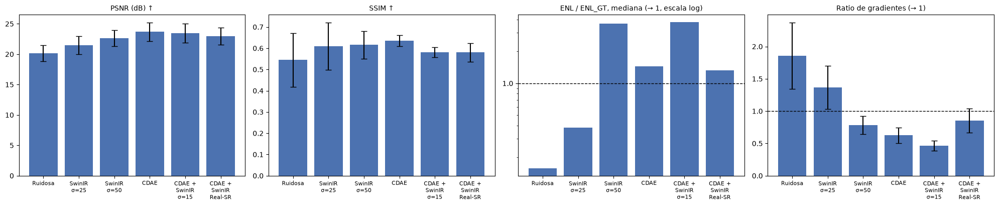

In [7]:
specs = [("PSNR", "PSNR (dB) ↑", None), ("SSIM", "SSIM ↑", None),
         ("ENL_RATIO", "ENL / ENL_GT, mediana (→ 1, escala log)", 1.0), ("GRAD_RATIO", "Ratio de gradientes (→ 1)", 1.0)]
labels = [v.replace(" + ", " +\n").replace(" σ", "\nσ").replace(" Real-SR", "\nReal-SR") for v in VERSIONES]
fig, axs = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, (col, title, ref) in zip(axs, specs):
    g = df.groupby("Versión", sort=False)[col]
    if col == "ENL_RATIO":
        ax.bar(range(len(VERSIONES)), g.median(), color="#4c72b0")
    else:
        ax.bar(range(len(VERSIONES)), g.mean(), yerr=g.std(), capsize=4, color="#4c72b0")
    ax.set_xticks(range(len(VERSIONES)), labels, fontsize=8)
    ax.set_title(title, fontsize=10)
    if ref:
        ax.axhline(ref, color="k", ls="--", lw=1)
axs[2].set_yscale("log")
axs[2].yaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
axs[2].yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
plt.tight_layout()
fig.savefig(RES / "metricas.png", dpi=150, bbox_inches="tight")
plt.show()

## Inspección visual

Por imagen: la imagen completa (el recuadro amarillo marca la zona con más bordes del GT), el zoom de esa zona, el mapa de |error| frente al GT y el mapa de bordes Sobel.

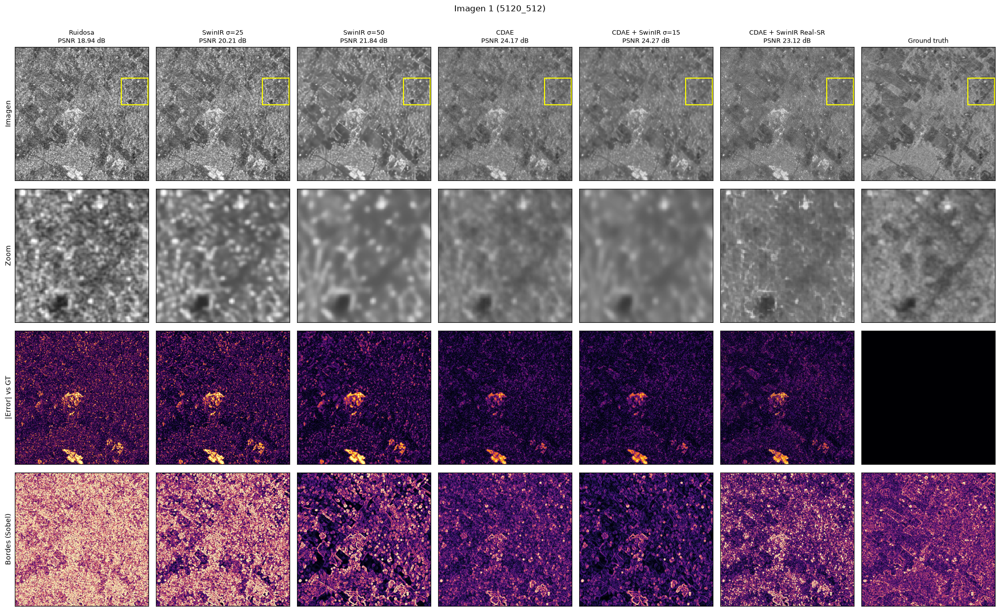

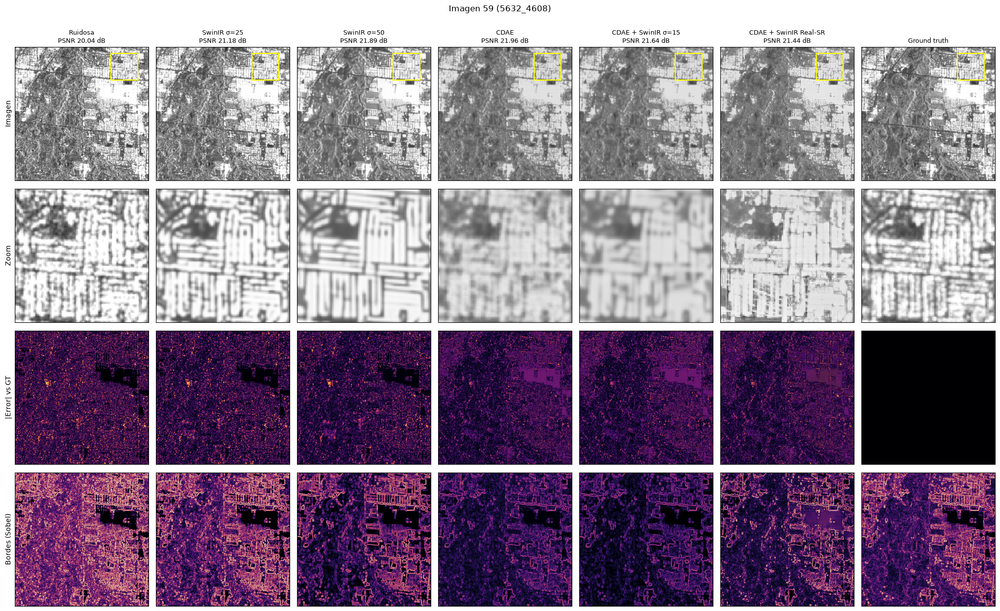

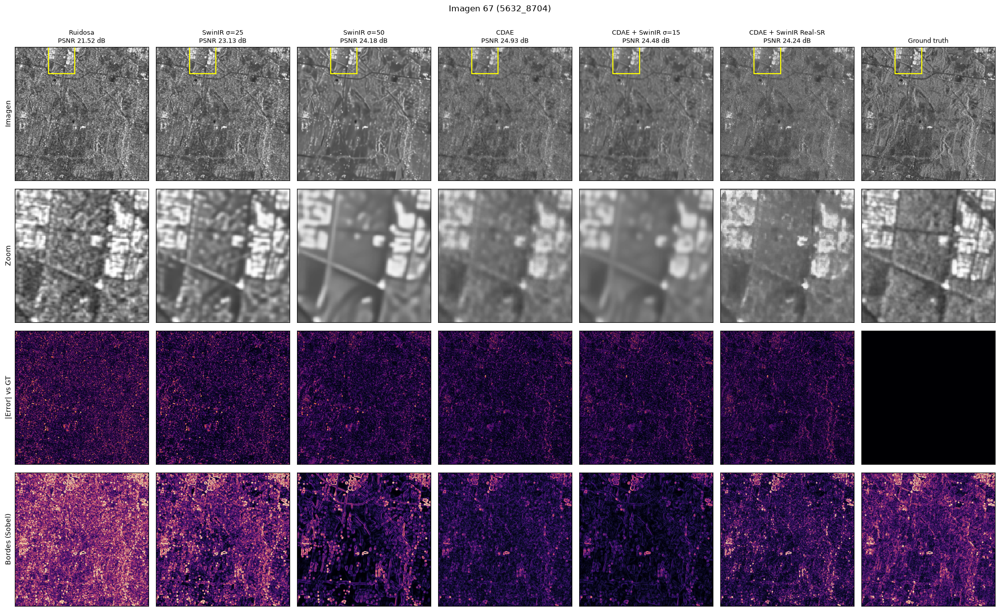

In [8]:
def detail_roi(g, size=96, stride=8):
    ii = cv2.integral(grad_mag(g).astype(np.float64))
    s = (ii[size:, size:] - ii[:-size, size:] - ii[size:, :-size] + ii[:-size, :-size])[::stride, ::stride]
    y, x = np.unravel_index(np.argmax(s), s.shape)
    return int(y * stride), int(x * stride)


def show_comparison(i):
    cols = list(VERSIONES.items()) + [("Ground truth", gt)]
    zs = 102
    y0, x0 = detail_roi(gt[i], zs)
    gmax = float(np.percentile(grad_mag(gt[i]), 99))
    fig, axs = plt.subplots(4, len(cols), figsize=(2.9 * len(cols), 12.4))
    for j, (name, imgs) in enumerate(cols):
        im = imgs[i]
        title = name if name == "Ground truth" else f"{name}\nPSNR {metrics(im, gt[i], rois[i])['PSNR']:.2f} dB"
        axs[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
        axs[0, j].add_patch(plt.Rectangle((x0, y0), zs, zs, fill=False, ec="yellow", lw=1.5))
        axs[0, j].set_title(title, fontsize=9)
        axs[1, j].imshow(im[y0:y0 + zs, x0:x0 + zs], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        axs[2, j].imshow(np.abs(im - gt[i]), cmap="inferno", vmin=0, vmax=100)
        axs[3, j].imshow(grad_mag(im), cmap="magma", vmin=0, vmax=gmax)
    for r, label in enumerate(["Imagen", "Zoom", "|Error| vs GT", "Bordes (Sobel)"]):
        axs[r, 0].set_ylabel(label, fontsize=10)
    for a in axs.ravel():
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"Imagen {IDX[i]} ({names[i]})", y=1.0)
    plt.tight_layout()
    fig.savefig(RES / f"comparacion_{IDX[i]}.png", dpi=100, bbox_inches="tight")
    plt.show()


for i in range(len(IDX)):
    show_comparison(i)

## Observaciones visuales

- **SwinIR σ=25** quita poco speckle: el grano sigue visible en las zonas homogéneas y el mapa de Sobel está casi tan saturado como el de la ruidosa (ratio de gradientes 1.37).
- **SwinIR σ=50** limpia el speckle y deja rectas las calles y los bloques urbanos de las imágenes 59 y 67. Pero en las zonas de cultivo y vegetación (imágenes 1 y 67) aparecen trazos curvos y manchas lisas que no están en el GT: es la textura de las imágenes naturales con las que se entrenó, no la del SAR. En Sobel se ven como bordes redondeados y zonas negras sin detalle.
- **CDAE** da la imagen más parecida al GT en intensidad, pero borrosa: se pierden las líneas finas de las parcelas (imagen 1) y la separación entre edificios (imagen 59). Además, en la zona saturada de la imagen 59 baja el blanco a gris, y el mapa de error muestra ese bloque uniforme.
- **CDAE + SwinIR σ=15** se ve igual o más borrosa que el CDAE solo. El denoising no tiene nada que quitar y termina suavizando lo poco que quedaba.
- **CDAE + SwinIR Real-SR** es la única versión que devuelve nitidez: reaparecen el contorno de los edificios, la carretera diagonal de la imagen 67 y el grano del terreno. Pero el detalle es inventado: la textura sale en bloques pequeños, y en la zona saturada de la imagen 59 aparece un patrón de cuadrícula que no existe en el GT (se ve en el zoom, en el mapa de error y en Sobel). Es el artefacto típico de un modelo entrenado con GAN.

## Conclusiones

1. **Ninguna versión con SwinIR supera al CDAE en las métricas.** El CDAE logra el mejor PSNR (23.69 dB) y SSIM (0.636). Aplicado directamente a la imagen ruidosa, SwinIR mejora la ruidosa (σ=50: +2.47 dB y +0.071 de SSIM), pero no llega al CDAE. Sus pesos están entrenados con ruido gaussiano aditivo, y el speckle es multiplicativo.
2. **Con σ=25 queda speckle y con σ=50 sobra suavizado.** El ENL pasa de 0.38 a 3.67 veces el del GT, y con σ=50 aparecen texturas que no existen en la escena.
3. **Restaurar la imagen filtrada con denoising empeora el resultado.** CDAE + SwinIR σ=15 baja el SSIM de 0.636 a 0.581, el ratio de gradientes de 0.62 a 0.46 y sube el ENL a 3.78 veces el del GT. Un modelo de denoising no recupera bordes, solo suaviza más.
4. **El Real-SR recupera nitidez, pero no fidelidad.** Sube el ratio de gradientes de 0.62 a 0.85 y deja el ENL cerca del GT (1.33). En cambio, baja el PSNR 0.75 dB, el SSIM 0.056 y la correlación de bordes (de 0.555 a 0.477): los bordes que añade no coinciden con los reales. Visualmente se ven bloques y un patrón de cuadrícula en las zonas saturadas.
5. **En SAR, un SwinIR preentrenado sin reentrenar mejora la apariencia a costa de inventar detalle.** Para usarlo en serio habría que ajustarlo con imágenes SAR. Son 3 imágenes y el GT es un promedio multitemporal, así que los números son indicativos y la inspección visual pesa tanto como las métricas.